# Refolio

Thin driver over `packages/converter` (CLI / Celery use the same pipeline).

**Fixtures:** synthetic PDF below, or place files in `notebooks/.local/` (gitignored). Never commit commercial books.

### Setup (optional extra — not in production Docker)

```bash
cd /path/to/refolio
python3 -m venv .venv && source .venv/bin/activate
pip install -e "packages/converter[dev,notebook,ocr]"  # Python 3.12/3.13; OCR for scanned PDFs
python -m ipykernel install --user --name refolio-converter --display-name "refolio-converter"
jupyter lab notebooks/dev_pipeline.ipynb
```

Notebook extras: `ipykernel`, `jupyterlab`, **PyMuPDF** (PDF→PNG preview), **bleach** (sanitized EPUB HTML).

In [1]:
import sys
print(sys.executable)  # debe ser .../refolio/.venv/bin/python

/Users/rbnetto/Projects/refolio/.venv/bin/python


In [8]:
# === Configuration (edit and re-run this cell) ===
from __future__ import annotations

from pathlib import Path

REPO_ROOT = Path("..").resolve()
LOCAL_DIR = REPO_ROOT / "notebooks" / ".local"
LOCAL_DIR.mkdir(parents=True, exist_ok=True)

# Private/local PDFs (gitignored). Pick a pool + index, or set PDF_PATH directly.
FACTURAS_DIR = LOCAL_DIR / "pdfs" / "facturas"
BOOK_PDF_CANDIDATES: list[Path] = [
    LOCAL_DIR / "cuatro-mil-semanas.pdf",
    LOCAL_DIR / "Ejercicios-Espirituales-Y-Filosofia-Antigua.pdf",
    LOCAL_DIR / "synthetic_dev.pdf",
]
FACTURA_CANDIDATES: list[Path] = [
    FACTURAS_DIR / "IMAG0007.PDF",
    FACTURAS_DIR / "IMAG0008.PDF",
    FACTURAS_DIR / "IMAG0009.PDF",
    FACTURAS_DIR / "IMAG0010.PDF",
    FACTURAS_DIR / "IMAG0011.PDF",
]
# "books" | "facturas"
PDF_POOL = "facturas"
PDF_INDEX = 1  # 1 = Ejercicios-Espirituales... (scanned; needs OCR)
BASELINE_EPUB = LOCAL_DIR / "epub" / "Ejercicios-Espirituales-Y-Filosofia-Antigua.epub"
CONVERTER_PKG = (REPO_ROOT / "packages" / "converter").resolve()
# OCR env (install cell below — use absolute CONVERTER_PKG, not cwd-relative packages/...)
import os
os.environ.setdefault("CONVERTER_OCR_ENGINE", "paddle")
os.environ.setdefault("CONVERTER_PADDLE_LANG", "es")
_POOL = FACTURA_CANDIDATES if PDF_POOL == "facturas" else BOOK_PDF_CANDIDATES
PDF_PATH: Path | None = _POOL[PDF_INDEX] if _POOL else None
LANGUAGE_HINT = "es"
MAX_PAGES: int | None = None  # e.g. 20 for a quick hillclimb pass on long books
RENDER_DPI = 120
RELOAD_ENGINE = False  # set True after editing packages/converter without kernel restart

if PDF_PATH is not None:
    PDF_PATH = Path(PDF_PATH).expanduser().resolve()

def _run_dir() -> Path:
    stem = PDF_PATH.stem if PDF_PATH else "run"
    out = LOCAL_DIR / "runs" / stem
    out.mkdir(parents=True, exist_ok=True)
    return out

OUTPUT_DIR = _run_dir()
PREVIEW_DIR = OUTPUT_DIR / "previews"
PREVIEW_DIR.mkdir(parents=True, exist_ok=True)
print("LOCAL:", LOCAL_DIR)
print("CONVERTER_PKG:", CONVERTER_PKG)
print("PDF:", PDF_PATH)
print("OUTPUT:", OUTPUT_DIR)

LOCAL: /Users/rbnetto/Projects/refolio/notebooks/.local
CONVERTER_PKG: /Users/rbnetto/Projects/refolio/packages/converter
PDF: /Users/rbnetto/Projects/refolio/notebooks/.local/pdfs/facturas/IMAG0008.PDF
OUTPUT: /Users/rbnetto/Projects/refolio/notebooks/.local/runs/IMAG0008


In [9]:
import importlib
import sys

if str(REPO_ROOT / "packages" / "converter" / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "packages" / "converter" / "src"))
if str(REPO_ROOT / "notebooks") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "notebooks"))

_ENGINE_MODULES = [
    "converter.adapters.factory",
    "converter.adapters.routed_pdf",
    "converter.editorial.pipeline",
    "converter.pipeline",
]

if RELOAD_ENGINE:
    for name in _ENGINE_MODULES:
        if name in sys.modules:
            importlib.reload(sys.modules[name])
    print("Reloaded engine modules:", _ENGINE_MODULES)

import json

from converter.adapters.factory import get_parser
from converter.contracts import ParseContext
from converter.editorial import apply_editorial_passes
from converter.ir.models import BlockType, DocumentIR
from converter.pipeline import ConversionPipeline

from nb_viewers import (
    compare_epub_pair,
    preview_epub_chapters,
    render_pdf_pages,
    show_images,
)

print("Imports OK")

Imports OK


### Install OCR into **this** Jupyter kernel (run once)

Do **not** run `!pip install -e "packages/converter[ocr]"` from `notebooks/` — pip cannot resolve that path. Use the cell below (`CONVERTER_PKG` + `sys.executable`).

In [10]:
import subprocess
import sys

from converter.adapters.ocr_deps import (
    missing_ocr_render_modules,
    missing_paddle_modules,
    pip_install_notebook_ocr,
    pip_install_render_quick,
)

render_missing = missing_ocr_render_modules()
paddle_missing = missing_paddle_modules()
if not render_missing and not paddle_missing:
    print("OCR deps OK in this kernel (numpy, pymupdf, paddleocr, paddle).")
else:
    print("Missing:", render_missing + paddle_missing)
    if render_missing:
        print("Quick render:", pip_install_render_quick())
    print("Full stack:", pip_install_notebook_ocr(CONVERTER_PKG))
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-e",
            f"{CONVERTER_PKG}[dev,notebook,ocr]",
        ]
    )
    import numpy

    print("numpy", numpy.__version__)

OCR deps OK in this kernel (numpy, pymupdf, paddleocr, paddle).


### Synthetic PDF (skip if `PDF_PATH` already exists)

In [11]:
from reportlab.lib.pagesizes import letter
from reportlab.pdfgen import canvas

synthetic = LOCAL_DIR / "synthetic_dev.pdf"
if PDF_PATH is None or not PDF_PATH.is_file():
    c = canvas.Canvas(str(synthetic), pagesize=letter)
    c.setFont("Helvetica", 12)
    c.drawString(72, 720, "Capítulo 1")
    c.drawString(72, 700, "Este párrafo sintético sirve para probar el motor.")
    c.showPage()
    c.drawString(72, 720, "Segunda página con texto de continuación")
    c.save()
    PDF_PATH = synthetic.resolve()
    OUTPUT_DIR = _run_dir()
    PREVIEW_DIR = OUTPUT_DIR / "previews"
    PREVIEW_DIR.mkdir(parents=True, exist_ok=True)

assert PDF_PATH and PDF_PATH.is_file(), "Set PDF_PATH or run synthetic cell"
print("Using PDF:", PDF_PATH)

Using PDF: /Users/rbnetto/Projects/refolio/notebooks/.local/pdfs/facturas/IMAG0008.PDF


## View source PDF (PNG previews)

Rendered 1 pages → /Users/rbnetto/Projects/refolio/notebooks/.local/runs/IMAG0008/previews/pdf_pages


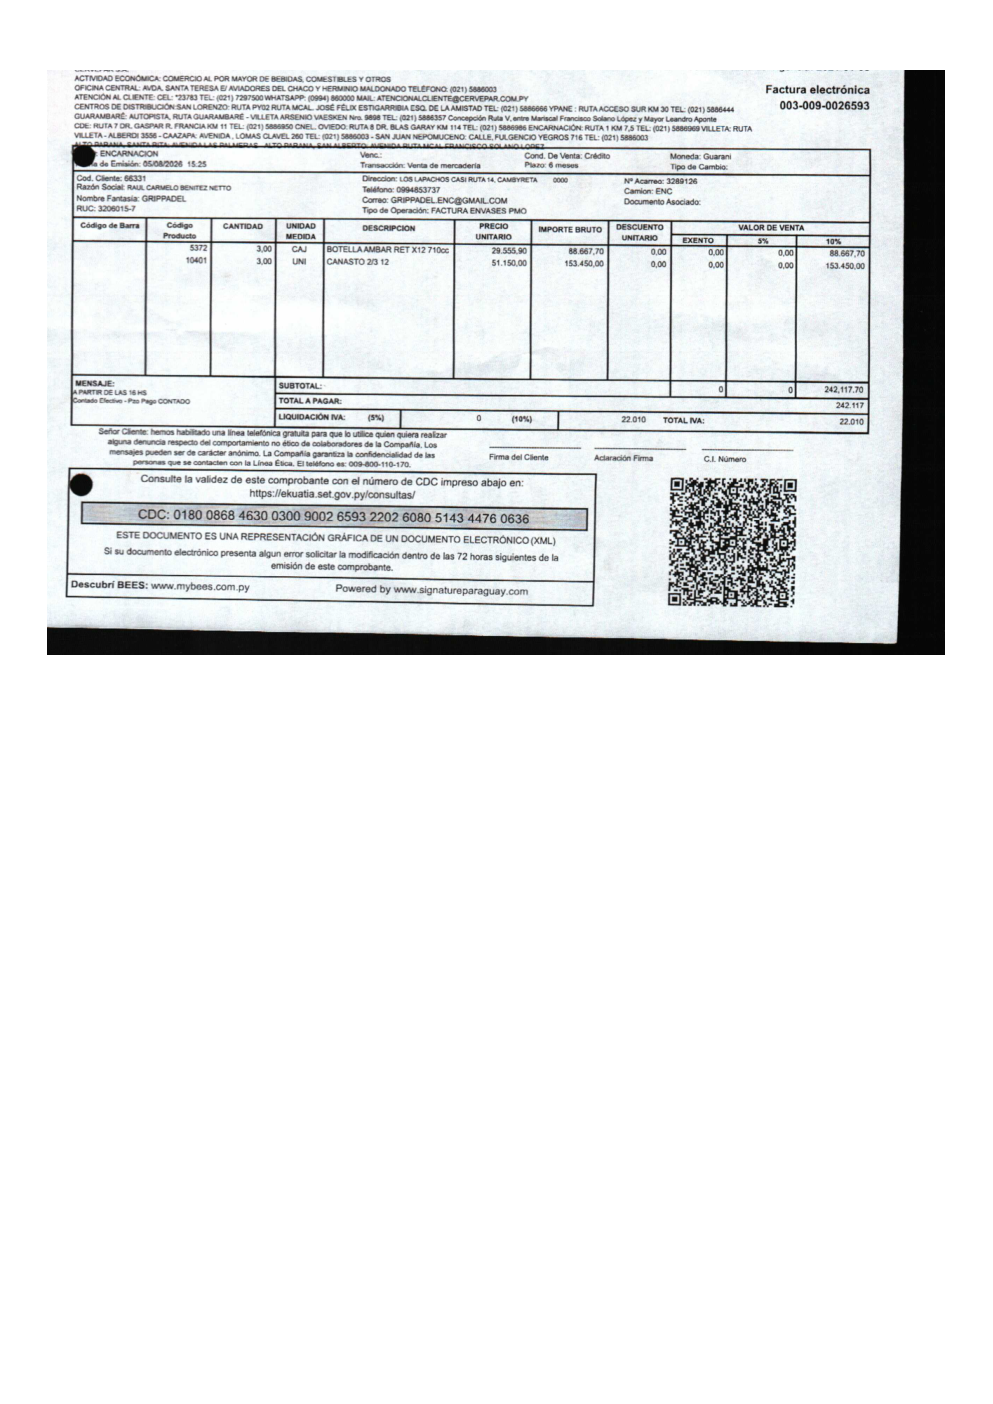

In [12]:
page_count_hint = MAX_PAGES or 8
indices = list(range(page_count_hint))
pdf_pngs = render_pdf_pages(
    PDF_PATH,
    PREVIEW_DIR / "pdf_pages",
    page_indices=indices,
    dpi=RENDER_DPI,
)
print("Rendered", len(pdf_pngs), "pages →", PREVIEW_DIR / "pdf_pages")
show_images(pdf_pngs)

## 1. Parse → raw IR

In [13]:
parser = get_parser()
ctx = ParseContext(source_path=PDF_PATH, language_hint=LANGUAGE_HINT, max_pages=MAX_PAGES)
raw_ir: DocumentIR = parser.parse(ctx)

print("Parser:", raw_ir.engine_trace.get("parser"), "| OCR:", raw_ir.engine_trace.get("ocr_engine"))
print("Schema:", raw_ir.schema_version, "| pages:", len(raw_ir.pages))
print("\n=== Page diagnostics / routing ===")
for d in raw_ir.page_diagnostics:
    sig = ", ".join(f"{k}={v}" for k, v in d.signals.items()) if d.signals else ""
    print(f"  p{d.page_index}: chars={d.char_count} alnum={d.alnum_ratio:.2f} route={d.route.value} {sig}")
print("\n=== Parse warnings ===")
for w in raw_ir.warnings:
    loc = f" p{w.page_index}" if w.page_index is not None else ""
    print(f"  [{w.code}]{loc} {w.message}")

Parser: routed_pdf | OCR: paddleocr
Schema: 0.2.0 | pages: 1

=== Page diagnostics / routing ===
  p0: chars=0 alnum=0.00 route=ocr_skipped_unavailable min_chars_native=24, min_alnum_ratio=0.35, low_text=True, low_alnum_ratio=True

=== Parse warnings ===
  [ocr_failed] p0 PaddleOCR failed: RuntimeError: (NotFound) No allocator found for the place, Place(undefined:0)
  [Hint: Expected iter != allocators.end(), but received iter == allocators.end().] (at /Users/paddle/xly/workspace/7b5bf7ed-f223-4c37-9311-a1c9d604457b/Paddle/paddle/phi/core/memory/allocation/allocator_facade.cc:381)
  [operator < matmul > error]
  [empty_page_text] p0 No extractable text on page after routing.


## 2. Editorial passes

In [ ]:
edited_ir = apply_editorial_passes(raw_ir)
from collections import Counter

print("Block types:", dict(Counter(b.block_type.value for b in edited_ir.blocks)))
print("Editorial trace:", edited_ir.engine_trace.get("editorial"))
print("\n=== Editorial warnings (new) ===")
for w in edited_ir.warnings[len(raw_ir.warnings):]:
    print(f"  [{w.code}] {w.message}")

In [ ]:
def text_diff_samples(raw: DocumentIR, edited: DocumentIR, limit: int = 8) -> None:
    raw_lines = [b for b in raw.sorted_blocks() if b.block_type == BlockType.LINE][:limit]
    edited_blocks = edited.sorted_blocks()[:limit]
    print("--- Before (LINE samples) ---")
    for b in raw_lines:
        print(f"  p{b.provenance.page_indices} | {b.current_text[:100]}")
    print("--- After (post-editorial) ---")
    for b in edited_blocks:
        pages = b.provenance.page_indices
        ch = len(b.change_history)
        print(f"  {b.block_type.value} p{pages} ch={ch} | {b.current_text[:100]}")

text_diff_samples(raw_ir, edited_ir)

print("\n=== Provenance / change_history ===")
for b in edited_ir.sorted_blocks():
    if not b.change_history:
        continue
    print(f"{b.id} ({b.block_type.value}): {b.current_text[:80]}")
    for ch in b.change_history:
        print(f"   {ch.op.value}: {ch.reason}")

## 3. Full pipeline → EPUB + quality

In [ ]:
pipeline_out = OUTPUT_DIR / "pipeline_run"
result = ConversionPipeline().run(
    source_pdf=PDF_PATH,
    output_dir=pipeline_out,
    language_hint=LANGUAGE_HINT,
    max_pages=MAX_PAGES,
    run_epubcheck_validation=True,
)

qr = result.quality_report.to_dict()
print("Engine:", result.engine_version)
print("EPUB:", result.epub_path, "| exists:", result.epub_path.is_file())
print("IR:", result.ir_path)
print("\n=== Quality summary ===")
for key in ("block_count", "page_count", "warning_count", "empty_block_count"):
    print(f"  {key}: {qr.get(key)}")
if qr.get("epub_validation"):
    print("  epub_validation:", qr["epub_validation"])
if qr.get("notes"):
    print("  notes:", qr["notes"])

snapshot = OUTPUT_DIR / "document.ir.snapshot.json"
snapshot.write_text(
    json.dumps(result.document_ir.model_dump(mode="json"), indent=2, ensure_ascii=False) + "\n",
    encoding="utf-8",
)
print("Snapshot:", snapshot)
print("\n=== engine_trace.quality_metrics ===")
print(json.dumps(result.document_ir.engine_trace.get("quality_metrics", {}), indent=2))

## View generated EPUB (sanitized HTML from artifact)

In [ ]:
if not result.epub_path.is_file():
    raise FileNotFoundError(f"No EPUB at {result.epub_path} — pipeline did not produce output")
preview_epub_chapters(result.epub_path, max_chapters=6, iframe_height=360)

## Optional: open a local PNG/JPG from `.local/`

In [ ]:
extra_images = sorted(
    p for p in LOCAL_DIR.glob("**/*") if p.suffix.lower() in {".png", ".jpg", ".jpeg"}
)
if extra_images:
    print("Images in .local:", [p.name for p in extra_images[:10]])
    show_images(extra_images[:4])
else:
    print("No extra PNG/JPG in .local — PDF page renders are under", PREVIEW_DIR)

## Baseline EPUB comparison (Ejercicios — local only)

Place the reference EPUB at `notebooks/.local/epub/Ejercicios-Espirituales-Y-Filosofia-Antigua.epub` (gitignored). Metrics only — no book text in git.

In [ ]:
from nb_viewers import epub_text_stats

if BASELINE_EPUB.is_file():
    print("Baseline stats:", epub_text_stats(BASELINE_EPUB))
else:
    print("Missing baseline:", BASELINE_EPUB)
    print("Copy from Downloads into notebooks/.local/epub/ (same basename).")

In [ ]:
if BASELINE_EPUB.is_file() and result.epub_path.is_file():
    comparison = compare_epub_pair(BASELINE_EPUB, result.epub_path)
    print(json.dumps(comparison, indent=2))
    if comparison["text_char_ratio"] < 0.05:
        from converter.adapters.ocr_deps import pip_install_notebook_ocr

        print(
            "\nHint: low text ratio usually means OCR is off or failed. "
            f"Install: {pip_install_notebook_ocr(CONVERTER_PKG)} then re-run with a small MAX_PAGES."
        )
else:
    print("Need both baseline EPUB and pipeline EPUB to compare.")

In [ ]:
if BASELINE_EPUB.is_file():
    print("=== Baseline preview (first chapters) ===")
    preview_epub_chapters(BASELINE_EPUB, max_chapters=2, iframe_height=280)
if result.epub_path.is_file():
    print("=== Refolio output preview ===")
    preview_epub_chapters(result.epub_path, max_chapters=2, iframe_height=280)